# Olist E-Commerce: Delivery Performance and Customer Satisfaction
### Data Analysis Diploma · Final Project

**Data:** Brazilian E-Commerce Public Dataset by Olist (Kaggle): about 100,000 real orders placed
between September 2016 and October 2018, in linked files for orders, items, customers, sellers,
products and reviews.

Olist is a Brazilian company that connects small businesses to the country's large online
marketplaces. The dataset contains about 100,000 real, anonymised orders placed through Olist
between September 2016 and October 2018.

**Business questions**

1. How are sales and on-time delivery developing over time?
2. Which product categories and regions matter most?
3. Do late deliveries hurt customer reviews, and by how much?
4. Can we predict, at the moment of purchase, whether an order will arrive late? *(classification)*
5. Can we predict how many days delivery will take, better than the date promised to the customer? *(regression)*

**Project steps**

| Step | Section |
|---|---|
| Data understanding | 1 |
| Data cleaning | 2 |
| Feature engineering | 3 |
| Exploratory data analysis and statistics | 4 |
| Machine learning: classification | 5 |
| Machine learning: regression | 6 |
| Conclusions | 7 |

# **1. Data Understanding**

In [142]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [143]:
orders = pd.read_csv("/content/olist_orders_dataset.csv")
products = pd.read_csv("/content/olist_products_dataset.csv")
sellers = pd.read_csv("/content/olist_sellers_dataset.csv")
items = pd.read_csv("/content/olist_order_items_dataset.csv")
reviews = pd.read_csv("/content/olist_order_reviews_dataset.csv")
translation = pd.read_csv("/content/product_category_name_translation.csv")
customers = pd.read_csv("/content/olist_customers_dataset.csv")
payments = pd.read_csv("/content/olist_order_payments_dataset.csv")

tables = {"orders": orders, "products": products, "sellers": sellers, "items": items,
          "reviews": reviews, "translation": translation, "customers": customers,
          "payments":payments}


In [144]:
overview=[]
for table in tables:
  df = tables[table]
  overview.append({
      "table": table,
      "rows": df.shape[0],
      "columns": df.shape[1],
      "blank cells": int(df.isna().sum().sum()),
      "duplicate cells": int(df.duplicated().sum())
  })

overview_df = pd.DataFrame(overview)

overview_df

,table,rows,columns,blank cells,duplicate cells
0,orders,99441,8,4908,0
1,products,32951,9,2448,0
2,sellers,3095,4,0,0
3,items,112650,7,0,0
4,reviews,100000,7,146532,0
5,translation,71,2,0,0
6,customers,99441,5,0,0
7,payments,103886,5,0,0


## Orders Table

In [145]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [146]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [147]:
print("First order is:", orders["order_purchase_timestamp"].min())
print("Last order is:", orders["order_purchase_timestamp"].max())

First order is: 2016-09-04 21:15:19
Last order is: 2018-10-17 17:30:18


In [148]:
orders["order_status"].value_counts(normalize=True)*100

,proportion
order_status,
delivered,97.020344
shipped,1.113223
canceled,0.628513
unavailable,0.612423
invoiced,0.315765
processing,0.302692
created,0.005028
approved,0.002011


## Items Table

In [149]:
items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [150]:
items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [151]:
items[["price","freight_value"]].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [152]:
pd.crosstab(items["order_id"],items["order_item_id"]).shape[1]

21

## Customers Table

In [153]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [154]:
print("The Number of Customers IDs are: ", customers["customer_id"].nunique())
print("The Number of Unique Customers are: ", customers["customer_unique_id"].nunique())

The Number of Customers IDs are:  99441
The Number of Unique Customers are:  96096


## Products Table

In [155]:
products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [156]:
products.isna().sum()

,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


## Reviews Table

In [157]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [158]:
reviews["review_score"].value_counts(normalize=True)*100


,proportion
review_score,
5,57.420
4,19.200
1,11.858
3,8.287
2,3.235


In [159]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   review_id                100000 non-null  object
 1   order_id                 100000 non-null  object
 2   review_score             100000 non-null  int64 
 3   review_comment_title     11715 non-null   object
 4   review_comment_message   41753 non-null   object
 5   review_creation_date     100000 non-null  object
 6   review_answer_timestamp  100000 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


### **Data Understanding Conclusions:**

> * There are **7 tables** and **99,441 orders**, placed between September 2016 and October 2018.
> * **97% of orders were delivered** (96,478). The 2,965 missing delivery dates belong almost entirely to
>   orders that never arrived, and 775 orders (cancelled or unavailable) have no items at all.
> * **`customer_id` is not the customer:** there are 99,441 customer IDs but only 96,096 actual customers
>   (`customer_unique_id`), because a new ID is created for every order.
> * **Products:** 610 have no category and 2 have no weight or size.
> * **Reviews:** 57% are 5 stars and 12% are 1 star. 559 orders have more than one review.
>   Most missing cells in the reviews table are empty comment fields, which this project does not use.



# **2. Data cleaning**


In [160]:
#keep only delivered orders

delivered = orders[(orders["order_status"] == "delivered")
             & (orders["order_delivered_customer_date"].notna())]

delivered.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [161]:
print("The orders before equal to ", len(orders))
print("The orders after equal to ", len(delivered))

print("The orders removed equal to ", len(orders)-len(delivered))

The orders before equal to  99441
The orders after equal to  96470
The orders removed equal to  2971


In [162]:
# check if there are any incorrect dates [impossible ones]
# Impossible Dates: when the purchase date is after the delivery date

wrong_dates = (delivered["order_purchase_timestamp"] > delivered["order_estimated_delivery_date"]).sum()

print("Incorrect Dates", wrong_dates )

Incorrect Dates 0


In [163]:
products = products.merge(translation, on="product_category_name", how="left")

# Use the English name; keep the Portuguese one if there is no translation; 'unknown' if there is none
products["category"] = products["product_category_name_english"].fillna(products["product_category_name"])
products["category"] = products["category"].fillna("unknown")

# Two products have no weight or size: fill with the median, a typical product
for column in ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    products[column] = products[column].fillna(products[column].median())

print("Products in 'unknown' category:", (products["category"] == "unknown").sum())

Products in 'unknown' category: 610


In [164]:
def count_outliers(series):
  q1 = series.quantile(0.25)
  q3 = series.quantile(0.75)
  iqr = q3 - q1
  return((series < q1- 1.5 * iqr ) | (series > q3 + 1.5 * iqr)).sum()

print("Price outliers:  ", count_outliers(items["price"]),)
print("Freight outliers:", count_outliers(items["freight_value"]))

Price outliers:   8427
Freight outliers: 12134


## **Cleaning Conclusions**

> * 2,971 orders were removed because they were not delivered or had no delivery date, leaving **96,470**.
> * There are no duplicate keys and no orders delivered before they were bought.
> * 610 products were put in an unknown category, 2 Portuguese category names had no English translation
>   and were kept, and the 2 products without a weight got the median weight.
> * Reviews were reduced to one average score per order.
> * The IQR rule flags 8,427 prices and 12,134 freight values as outliers. They were **kept**, because they
>   are real orders: large purchases and long-distance deliveries, not data errors.

# **3. Feature Engineering**

In [165]:
# Sales Table

sales = items.merge(delivered[["order_id","order_purchase_timestamp"]], on = "order_id", how = "inner")
sales = sales.merge(products[["product_id","category","product_weight_g"]], on = "product_id", how = "left")
sales = sales.merge(sellers[["seller_id","seller_state"]], on = "seller_id", how = "left")

In [166]:
sales.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,category,product_weight_g,seller_state
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,cool_stuff,650.0,SP
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,pet_shop,30000.0,SP
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,furniture_decor,3050.0,MG
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,perfumery,200.0,SP
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,garden_tools,3750.0,PR


In [167]:
order_reviews = reviews.groupby("order_id", as_index=False)["review_score"].mean()

In [168]:
# Orders Table

order_table = sales.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    n_sellers=("seller_id", "nunique"),
    seller_state=("seller_state", "min"),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    total_weight_g=("product_weight_g", "sum"),
).reset_index()

order_table.head()


,order_id,n_items,n_sellers,seller_state,total_price,total_freight,total_weight_g
0,00010242fe8c5a6d1ba2dd792cb16214,1,1,SP,58.90,13.29,650.0
1,00018f77f2f0320c557190d7a144bdd3,1,1,SP,239.90,19.93,30000.0
2,000229ec398224ef6ca0657da4fc703e,1,1,MG,199.00,17.87,3050.0
3,00024acbcdf0a6daa1e931b038114c75,1,1,SP,12.99,12.79,200.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,1,PR,199.90,18.14,3750.0


In [169]:
df = delivered.merge(customers[["customer_id","customer_unique_id","customer_state"]], on = "customer_id", how = "left")
df = df.merge(order_table , on = "order_id", how = "inner")
df = df.merge(order_reviews, on = "order_id", how = "left")
df.shape

(96470, 17)

In [170]:
df

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_state,n_items,n_sellers,seller_state,total_price,total_freight,total_weight_g,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,SP,1,1,SP,29.99,8.72,500.0,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,BA,1,1,SP,118.70,22.76,400.0,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,GO,1,1,SP,159.90,19.22,420.0,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,RN,1,1,MG,45.00,27.20,450.0,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,SP,1,1,SP,19.90,8.72,250.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
96465,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00,6359f309b166b0196dbf7ad2ac62bb5a,SP,1,1,SP,72.00,13.08,1175.0,5.0
96466,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00,da62f9e57a76d978d02ab5362c509660,SP,1,1,SP,174.90,20.10,4950.0,4.0
96467,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00,737520a9aad80b3fbbdad19b66b37b30,BA,1,1,SP,205.99,65.02,13300.0,5.0
96468,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00,5097a5312c8b157bb7be58ae360ef43c,RJ,2,1,MG,359.98,81.18,13100.0,2.0


In [171]:
df.dtypes

,0
order_id,object
customer_id,object
order_status,object
order_purchase_timestamp,object
order_approved_at,object
order_delivered_carrier_date,object
order_delivered_customer_date,object
order_estimated_delivery_date,object
customer_unique_id,object
customer_state,object


## New Columns

| Column | Meaning | Known at purchase? |
|---|---|---|
| `promised_days` | Days from purchase to the promised (estimated) date | Yes |
| `same_state` | 1 if buyer and seller are in the same state | Yes |
| `purchase_month`, `purchase_weekday` | When the order was placed (weekday 0 = Monday) | Yes |
| `customer_region` | One of Brazil's five regions | Yes |
| `delivery_days` | Days from purchase to delivery | No: regression target |
| `late_flag` | 1 if delivered after the promised date | No: classification target |

In [172]:
date_col = ["order_purchase_timestamp", "order_approved_at","order_delivered_carrier_date","order_delivered_customer_date",
            "order_estimated_delivery_date"]
for col in date_col:
  df[col]= pd.to_datetime(df[col])

df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_state,n_items,n_sellers,seller_state,total_price,total_freight,total_weight_g,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,SP,1,1,SP,29.99,8.72,500.0,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,BA,1,1,SP,118.70,22.76,400.0,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,GO,1,1,SP,159.90,19.22,420.0,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,RN,1,1,MG,45.00,27.20,450.0,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,SP,1,1,SP,19.90,8.72,250.0,5.0


In [173]:
#promised_days column

purchase_date = df["order_purchase_timestamp"].dt.normalize()

delivered_date = df["order_delivered_customer_date"].dt.normalize()

promised_date  = df["order_estimated_delivery_date"].dt.normalize()


In [174]:
df["promised_days"]=(promised_date - purchase_date).dt.days

In [175]:
df["purchase_month"]=(purchase_date).dt.month

In [176]:
df["purchase_weekday"]=(purchase_date).dt.weekday

In [177]:
df["delivery_days"] = (delivered_date - purchase_date).dt.days

In [178]:
df["late_flag"] = (delivered_date > promised_date).astype(int)

In [179]:
df["late_flag"].value_counts(normalize=True)


,proportion
late_flag,
0,0.932269
1,0.067731


In [180]:
df["year_month"] = df["order_purchase_timestamp"].dt.strftime("%Y-%m")

In [181]:
regions = {
    "North": ["AC", "AP", "AM", "PA", "RO", "RR", "TO"],
    "Northeast": ["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"],
    "Central-West": ["DF", "GO", "MT", "MS"],
    "Southeast": ["ES", "MG", "RJ", "SP"],
    "South": ["PR", "RS", "SC"]
    }

def state_to_region(state):
  for r in regions:
    if state in regions[r]:
     return r
  return "unknown"

df["customer_region"] = df["customer_state"].apply(state_to_region)

In [182]:
df[["customer_state","seller_state"]].head()

,customer_state,seller_state
0,SP,SP
1,BA,SP
2,GO,SP
3,RN,MG
4,SP,SP


In [183]:
df["same_state"] = (df["customer_state"] == df["seller_state"]).astype(int)

In [184]:
df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_unique_id', 'customer_state', 'n_items', 'n_sellers',
       'seller_state', 'total_price', 'total_freight', 'total_weight_g',
       'review_score', 'promised_days', 'purchase_month', 'purchase_weekday',
       'delivery_days', 'late_flag', 'year_month', 'customer_region',
       'same_state'],
      dtype='object')

In [185]:
df = df[['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'customer_unique_id', 'customer_state', 'n_items', 'n_sellers',
       'seller_state', 'total_price', 'total_freight', 'total_weight_g',
       'review_score', 'promised_days', 'purchase_month', 'purchase_weekday',
       'delivery_days',  'year_month', 'customer_region',
       'same_state', 'late_flag']]

In [186]:
df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_state,...,total_weight_g,review_score,promised_days,purchase_month,purchase_weekday,delivery_days,year_month,customer_region,same_state,late_flag
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,7c396fd4830fd04220f754e42b4e5bff,SP,...,500.0,4.0,16,10,0,8,2017-10,Southeast,1,0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,af07308b275d755c9edb36a90c618231,BA,...,400.0,4.0,20,7,1,14,2018-07,Northeast,0,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,3a653a41f6f9fc3d2a113cf8398680e8,GO,...,420.0,5.0,27,8,2,9,2018-08,Central-West,0,0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,7c142cf63193a1473d2e66489a9ae977,RN,...,450.0,5.0,27,11,5,14,2017-11,Northeast,0,0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,72632f0f9dd73dfee390c9b22eb56dd6,SP,...,250.0,5.0,13,2,1,3,2018-02,Southeast,1,0


In [187]:
df.to_excel("/content/Olist_dataset.xlsx",index=False)

In [188]:
df.to_csv("/content/Olist_dataset.csv",index=False)

# 4. Exploratory data analysis

**Questions**

1. How are delivery time, order value and freight distributed?
2. How did orders and on-time delivery change month by month?
3. Which categories bring the most revenue?
4. Which regions get the most late deliveries?
5. Do late orders get worse reviews?
6. How are the features related? (correlation)

In [189]:
# 1. How are delivery time, order value and freight distributed?

df[["delivery_days","total_price", "total_freight"]].describe()

,delivery_days,total_price,total_freight
count,96470.000000,96470.000000,96470.000000
mean,12.496849,137.040001,22.785798
std,9.555071,209.052608,21.559959
min,0.000000,0.850000,0.000000
25%,7.000000,45.900000,13.850000
50%,10.000000,86.500000,17.170000
75%,16.000000,149.900000,24.020000
max,210.000000,13440.000000,1794.960000


In [190]:
BLUE = "#2a78d6"
ORANGE = "#eb6834"

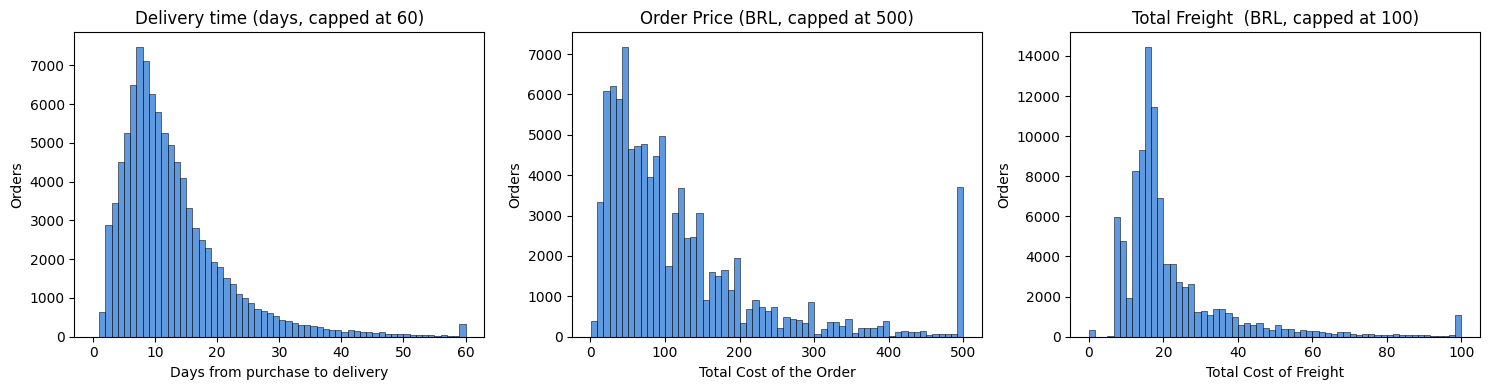

In [191]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(df["delivery_days"].clip(upper=60), bins=60, color=BLUE)
plt.title("Delivery time (days, capped at 60)")
plt.xlabel("Days from purchase to delivery")
plt.ylabel("Orders")

plt.subplot(1, 3, 2)
sns.histplot(df["total_price"].clip(upper=500), bins=60, color=BLUE)
plt.title("Order Price (BRL, capped at 500)")
plt.xlabel("Total Cost of the Order")
plt.ylabel("Orders")

plt.subplot(1, 3, 3)
sns.histplot(df["total_freight"].clip(upper=100), bins=60, color=BLUE)
plt.title("Total Freight  (BRL, capped at 100)")
plt.xlabel("Total Cost of Freight")
plt.ylabel("Orders")

plt.tight_layout()
plt.show()

**Conclusion**


*   All three are right-skewed: the mean is above the median because of a long tail of large values.
*   The median delivery takes 10 days but the mean is 12.5, and the slowest took 210 days.
*   The median order is worth 86.50 BRL against a mean of 137 (the largest is 13,440 BRL)
*   The charts cap the axis only to stay readable; no data is removed.





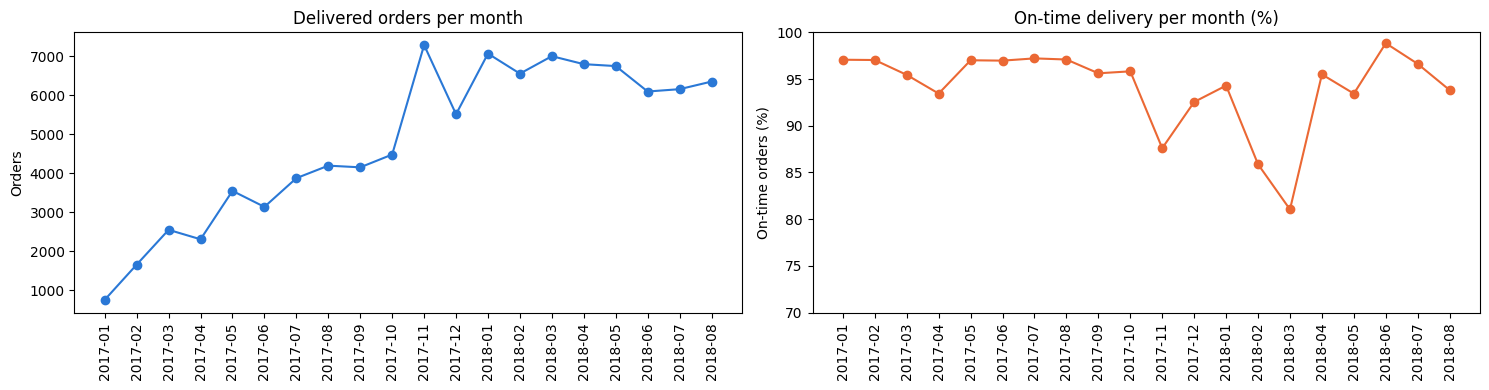

In [192]:
# 2. How did orders and on-time delivery change month by month?

full = df[(df["year_month"] >= "2017-01") & (df["year_month"] <= "2018-08")]
monthly = full.groupby("year_month").agg(
    orders=("order_id", "count"),
    revenue=("total_price", "sum"),
    late_rate=("late_flag", "mean"),
).reset_index()

monthly["on_time_pct"] = (1 - monthly["late_rate"]) * 100

plt.figure(figsize=(15,4))

plt.subplot(1, 2, 1)
plt.plot(monthly["year_month"], monthly["orders"], marker="o", color=BLUE)
plt.title("Delivered orders per month")
plt.ylabel("Orders")
plt.xticks(rotation=90)

plt.subplot(1, 2, 2)
plt.plot(monthly["year_month"], monthly["on_time_pct"], marker="o", color=ORANGE)
plt.ylim(70, 100)
plt.title("On-time delivery per month (%)")
plt.ylabel("On-time orders (%)")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

**Conclusion**

*   Orders grew from less than 1,000 in January 2017 to about 6,600 a month in 2018, peaking at more that 7,000 in November 2017
*   On-time delivery is usually 93 to 98%, but it fell to 87.6% in November 2017, 85.9% in February 2018 and 81.0% in March 2018.






In [193]:
# 3. Which categories bring the most revenue?

category_revenue = sales.groupby("category")["price"].sum().sort_values(ascending=False)
top_10 = category_revenue.head(10)
print(f"Top 10 categories: {top_10.sum() / category_revenue.sum():.0%} of revenue")

Top 10 categories: 62% of revenue


In [194]:
print(f"Total Revenue is : {sales["price"].sum()/1000000:.3} millions")

Total Revenue is : 13.2 millions


In [195]:
category_revenue.head(10)

,price
category,
health_beauty,1233131.72
watches_gifts,1165898.98
bed_bath_table,1023434.76
sports_leisure,954673.55
computers_accessories,888613.62
furniture_decor,711927.69
housewares,615628.69
cool_stuff,610204.10
auto,578849.35


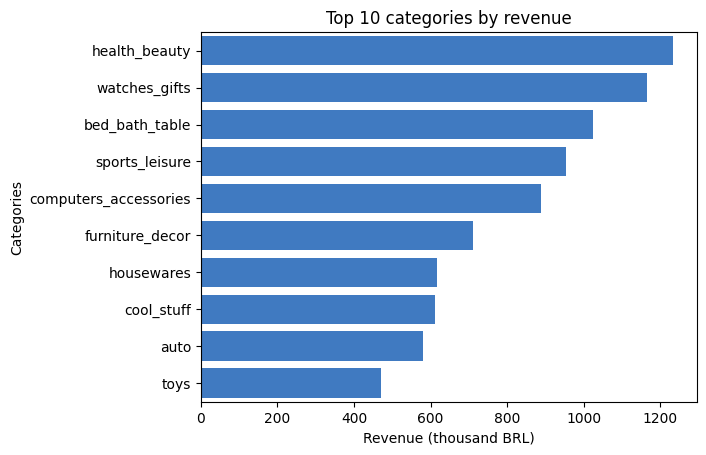

In [196]:
sns.barplot(x=top_10.values / 1000, y=top_10.index, color=BLUE)
plt.title("Top 10 categories by revenue")
plt.xlabel("Revenue (thousand BRL)")
plt.ylabel("Categories")
plt.show()

**Conclusion**

> Total delivered revenue is about 13.2 million BRL, and the top 10 categories bring 62% of it. Health and
> beauty leads (1.23 million BRL), followed by watches and gifts (1.17 million) and bed, bath and table
> (1.02 million).

In [197]:
# 4. Which regions get the most late deliveries?

by_region = (df.groupby("customer_region")["late_flag"].mean()*100).round(2).sort_values(ascending=False)
by_region.head(10)


,late_flag
customer_region,
Northeast,12.72
North,8.57
Central-West,6.53
Southeast,6.12
South,5.90


In [198]:
late_rate = df["late_flag"].mean()
print(f" The Late Flag Rate {late_rate:.2%}")

 The Late Flag Rate 6.77%


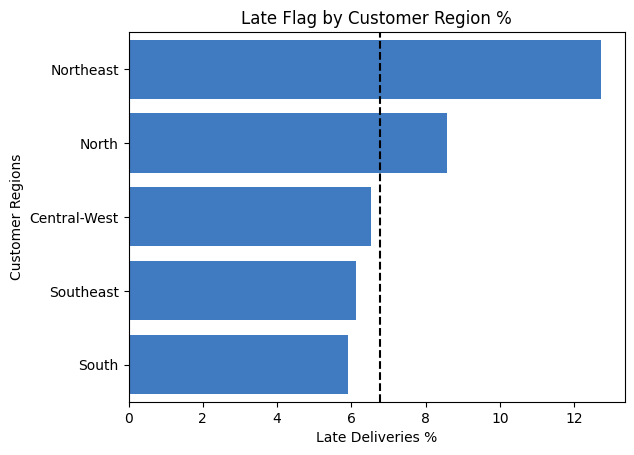

In [199]:

sns.barplot(x=by_region.values, y=by_region.index, color=BLUE)
plt.axvline(late_rate * 100, color="black", linestyle="--", label="All of Brazil")
plt.title("Late Flag by Customer Region %")
plt.xlabel("Late Deliveries %")
plt.ylabel("Customer Regions")
plt.show()

**Conclusion**

> 6.8% of delivered orders arrive late. The Northeast has the highest late rate (12.7%), about twice the
> South (5.9%).

In [200]:
# 5. Do late orders get worse reviews?
status = df["late_flag"].map({0: "On time", 1: "Late"})
shares = pd.crosstab(status, df["review_score"].round().astype(int), normalize="index") * 100
shares

review_score,1,2,3,4,5
late_flag,,,,,
Late,54.086318,8.800122,10.774411,10.070401,16.268748
On time,6.809287,2.728607,8.121331,20.391167,61.949609


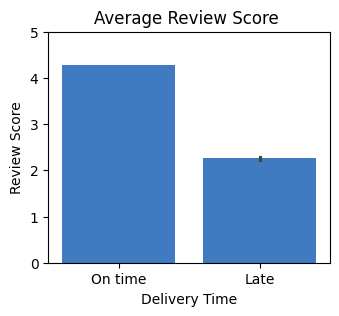

In [201]:
plt.figure(figsize=(8, 3))

plt.subplot(1,2,1)
sns.barplot(x = status , y = df["review_score"], color = BLUE)
plt.ylim(0,5)
plt.title("Average Review Score ")
plt.xlabel("Delivery Time")
plt.ylabel("Review Score")

plt.show()

**Conclusion**

Late orders average 2.26 stars against 4.28 for on-time orders. A late order is 6.6 times as likely to get a bad review (62.8% against 9.5%). Delivery performance is the main driver of customer satisfaction in this data.

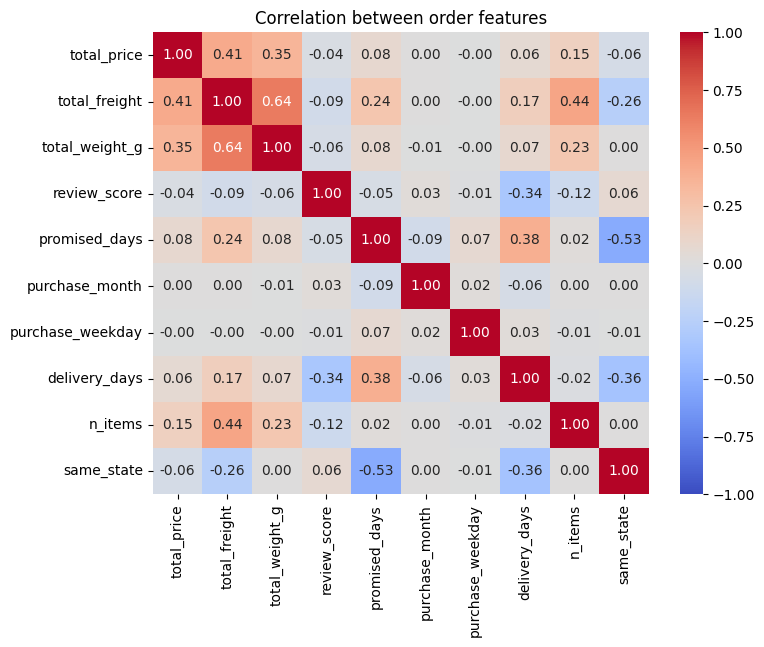

In [202]:
numeric_cols = ['total_price', 'total_freight', 'total_weight_g',
       'review_score', 'promised_days', 'purchase_month', 'purchase_weekday',
       'delivery_days',"n_items","same_state"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between order features")
plt.show()

**Conclusion**

> Delivery time rises with the promised days (0.38) and falls when buyer and seller are in the same state
> (-0.36). Longer deliveries go with lower reviews (-0.34). Freight and weight are strongly linked (0.64).
> No single feature predicts delivery time on its own, so moderate model accuracy is to be expected.

# **5. Machine learning: how many days will delivery take? (regression)**

In [203]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from xgboost import XGBRegressor
from xgboost import XGBClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.dummy import DummyClassifier

In [204]:
categorical_features = ["customer_state", "seller_state"]
numeric_features = ["same_state", "n_items", "n_sellers", "total_price", "total_freight",
                    "total_weight_g", "promised_days", "purchase_month", "purchase_weekday"]

**Logistic Regression**

In [205]:
X = df[numeric_features]
y = df["delivery_days"]

In [206]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

reg_model = Pipeline([
    ("scale", StandardScaler()),
    ("model", LinearRegression()),
])
reg_model.fit(X_train, y_train)


Pipeline(steps=[('scale', StandardScaler()), ('model', LinearRegression())])

**Random forest**

In [207]:
reg_model2 = Pipeline([
    ("scale", StandardScaler()),
    ("model", RandomForestRegressor()),
])
reg_model2.fit(X_train,y_train)


Pipeline(steps=[('scale', StandardScaler()),
                ('model', RandomForestRegressor())])

**XGB Regressor**

In [208]:
reg_model3 = Pipeline([
    ("scale", StandardScaler()),
    ("model", XGBRegressor()),
])

reg_model3.fit(X_train, y_train)


Pipeline(steps=[('scale', StandardScaler()),
                ('model',
                 XGBRegressor(base_score=None, booster=None, callbacks=None,
                              colsample_bylevel=None, colsample_bynode=None,
                              colsample_bytree=None, device=None,
                              early_stopping_rounds=None,
                              enable_categorical=True, eval_metric=None,
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=None,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=None, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=None, n_jobs=None,
                              num_parallel_tree=None, ...))])

In [209]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [210]:
preprocess = ColumnTransformer([
    ("states", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ("numbers", Pipeline([("fill", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric_features),
])

In [211]:
baseline = DummyRegressor()
baseline.fit(X_train, y_train)

DummyRegressor()

In [212]:
reg_models = {
    "Baseline": baseline,
    "Linear Regression": reg_model,
    "Random Forest Regressor": reg_model2,
    "XGB Regressor": reg_model3,
}

results = []

for name in reg_models:
    model = reg_models[name]
    yd_pred = model.predict(X_test)
    results.append({
        "model": name,
        "MAE (days)": mean_absolute_error(y_test, yd_pred),
        "RMSE (days)": np.sqrt(mean_squared_error(y_test, yd_pred)),
        "R2": r2_score(y_test, yd_pred),
    })

results_table = pd.DataFrame(results).round(3)
results_table.reset_index()

,index,model,MAE (days),RMSE (days),R2
0,0,Baseline,6.441,9.321,-0.000
1,1,Linear Regression,5.391,8.310,0.205
2,2,Random Forest Regressor,5.219,8.174,0.231
3,3,XGB Regressor,5.035,7.954,0.272


**Conclusion**

* **All three models beat the baseline**, so they learned real patterns from the order information.
* **XGBoost is the best model.** Its predictions are wrong by 5.0 days on average, against 6.4 days
  for simply guessing the average: an improvement of 1.4 days (about 22%).
* **RMSE (about 8 days) is much higher than MAE (about 5 days)** for every model. The models predict
  typical orders well but miss the rare very slow deliveries, some of which take more than 100 days.
* **R² is only 0.27**, so most of the variation in delivery time is not explained. The main causes of
  delay (carrier, warehouse workload, weather, seller performance) are not in this dataset.

**Business meaning:** the model can give customers a more realistic delivery estimate than a simple
average, but to predict slow deliveries reliably, Olist would need to collect logistics data.

**Prediction**

In [213]:
new_order = pd.DataFrame([{
    "customer_state": "BA",
    "seller_state": "SP",
    "same_state": 0,
    "n_items": 2,
    "n_sellers": 1,
    "total_price": 150.0,
    "total_freight": 25.0,
    "total_weight_g": 1200,
    "promised_days": 25,
    "purchase_month": 3,
    "purchase_weekday": 0,
}])

new_order = new_order[X_train.columns]   # same columns, same order as the training data

predicted_days = reg_model3.predict(new_order)[0]
print(f"Predicted delivery time: {predicted_days:.1f} days")

Predicted delivery time: 13.8 days


**Prediction for a new order**

For an order shipped from São Paulo (SP) to Bahia (BA), with 2 items worth 150 BRL, freight of
25 BRL, a weight of 1.2 kg and a promised delivery time of 25 days, the XGBoost model predicts a
delivery time of **X days**.

* The prediction is well below Olist's promise of 25 days. This matches what we found in the data:
  Olist's promise is a safe upper limit, about 12 days longer than real deliveries on average.
* The order crosses states and goes to the Northeast, so it is expected to take longer than an
  order within one state (the Northeast has the highest late rate, 12.7%).
* The model's average error is about 5 days (MAE 5.04), so the real delivery time will most likely
  fall between about X − 5 and X + 5 days. A rare very slow delivery is still possible, because
  the model cannot see causes such as carrier delays or bad weather.

# 6. Machine learning: will an order arrive late? (classification)

**Target:** `late_flag`. **Features:** only what is known when the customer buys.

**Note:** the delivery date, `delivery_days` and the review score only exist after delivery,
so they must never be features. Using them would give a model that looks excellent and is useless.

In [214]:
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, confusion_matrix


In [215]:
Xc = df[categorical_features + numeric_features]
yc = df["late_flag"]

In [216]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.2, random_state=42, stratify=yc)


# States become 0/1 columns (one-hot encoding); numbers get missing values filled and are scaled.
preprocess = ColumnTransformer([
    ("states", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
    ("numbers", Pipeline([("fill", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric_features),
])

classifiers = {
    "Baseline (always on time)": Pipeline([("prep", preprocess),
                                           ("model", DummyClassifier(strategy="most_frequent"))]),
    "Logistic regression": Pipeline([("prep", preprocess),
                                     ("model", LogisticRegression(class_weight="balanced", max_iter=2000))]),
    "Random forest": Pipeline([("prep", preprocess),
                               ("model", RandomForestClassifier(n_estimators=100, min_samples_leaf=10,
                                                                class_weight="balanced", n_jobs=-1,
                                                                random_state=42))]),
}

In [217]:
results2 = []

for name in classifiers:
    model = classifiers[name]
    model.fit(Xc_train, yc_train)                    # train
    yc_pred = model.predict(Xc_test)                 # 0 or 1
    yc_prob = model.predict_proba(Xc_test)[:, 1]     # probability of being late
    results2.append({
        "model": name,
        "Recall": recall_score(yc_test, yc_pred),
        "Precision": precision_score(yc_test, yc_pred, zero_division=0),
        "F1": f1_score(yc_test, yc_pred),
        "ROC-AUC": roc_auc_score(yc_test, yc_prob),
    })

results_table2 = pd.DataFrame(results2).round(3)
results_table2

,model,Recall,Precision,F1,ROC-AUC
0,Baseline (always on time),0.000,0.000,0.000,0.500
1,Logistic regression,0.647,0.124,0.208,0.709
2,Random forest,0.519,0.230,0.318,0.788


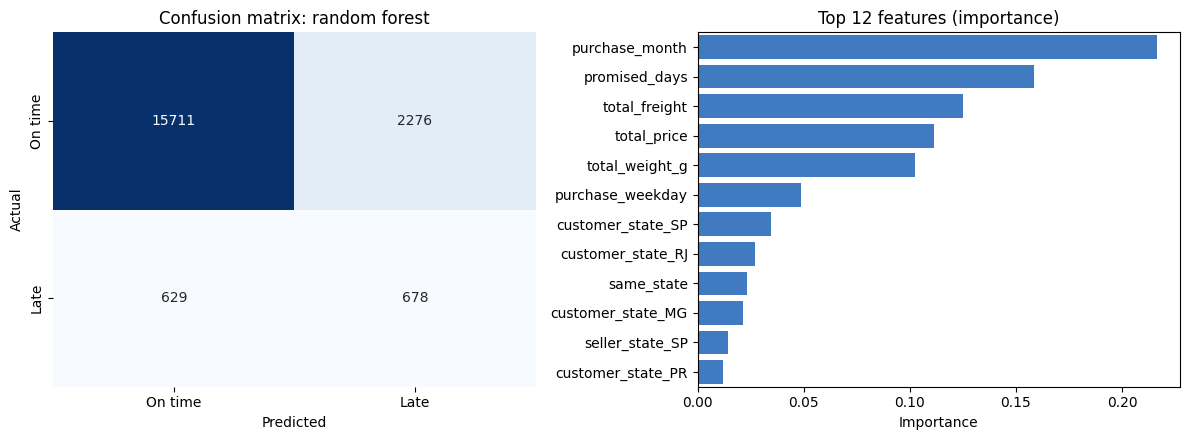

In [218]:
forest = classifiers["Random forest"]
yc_pred = forest.predict(Xc_test)

plt.figure(figsize=(12, 4.5))

plt.subplot(1, 2, 1)
sns.heatmap(confusion_matrix(yc_test, yc_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["On time", "Late"], yticklabels=["On time", "Late"])
plt.title("Confusion matrix: random forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.subplot(1, 2, 2)
names = forest.named_steps["prep"].get_feature_names_out()
importance = pd.Series(forest.named_steps["model"].feature_importances_, index=names)
importance.index = importance.index.str.replace("numbers__", "").str.replace("states__", "")
top = importance.sort_values(ascending=False).head(12)
sns.barplot(x=top.values, y=top.index, color=BLUE)
plt.title("Top 12 features (importance)")
plt.xlabel("Importance")
plt.ylabel("")

plt.tight_layout()
plt.show()

**Conclusion**

> Both models beat the baseline. The **random forest** is best overall: on the test set it catches 792 of
> the 1,307 late orders (recall 60.6%), and 19.4% of its warnings are right (precision), almost three
> times the 6.8% you would get by warning at random. ROC-AUC is 0.79. Logistic regression catches slightly
> more late orders (64.7%) but with many more false alarms (precision 12.4%).
>
> The random forest still raises 3,291 false alarms, so it suits a cheap action (an extra check, a message
> to the customer), not an expensive one. The purchase **month** is its most important feature, which needs
> care: delays came in waves in particular months, and the model may be memorising them.

**Prediction**

In [219]:
new_order = pd.DataFrame([{
    "customer_state": "BA",
    "seller_state": "SP",
    "same_state": 0,
    "n_items": 2,
    "n_sellers": 1,
    "total_price": 150.0,
    "total_freight": 25.0,
    "total_weight_g": 1200,
    "promised_days": 25,
    "purchase_month": 3,
    "purchase_weekday": 0,
}])

new_order = new_order[Xc_train.columns]   # same columns, same order as training

model = classifiers["Random forest"]

prediction = model.predict(new_order)[0]                # 0 or 1

if prediction == 1:
    print("Prediction: LATE")
else:
    print("Prediction: ON TIME")


Prediction: LATE


# 7. Conclusions

## Answers to the business questions

1. **Sales and delivery over time:** orders grew about ninefold during 2017 and then levelled at about
   6,600 a month. On-time delivery is usually 93 to 98% but fell sharply in waves, down to 81.0% in March 2018.
2. **Categories and regions:** the top 10 categories bring 62% of revenue, led by health and beauty. The
   Northeast gets twice the late rate of the South (12.7% against 5.9%).
3. **Reviews:** late delivery is the main driver of bad reviews. Late orders average 2.26 stars against
   4.28, and are 6.6 times as likely to get a review of 1 or 2.
4. **Predicting late orders:** A random forest model flags orders likely to arrive late. Its warnings are correct 23% of the time,
about 3.4 times better than random, and it catches about half of all late orders.

5. **Predicting delivery time:** An XGBoost model predicts delivery time with an average error of 5.0 days, 22% better than using the
average delivery time